# ПЗ-3. Мини-LLaVA: обучение проектора

Два независимых проектора, замороженные SigLIP и Qwen2.5. Полный эксперимент: 20 000 пар COCO train, 500 изображений val, одна эпоха для каждого варианта. Требуется Colab GPU T4 и несколько часов. Результаты и веса сохраняются в рабочей папке Colab; для долгого прогона рекомендуется подключить Google Drive и скопировать туда контрольные точки.

In [1]:
# Проверка устройства, на котором выполняется ноутбук
import sys, os, platform, shutil, subprocess
IN_COLAB = 'google.colab' in sys.modules or os.path.isdir('/content')
print('Среда:', 'Google Colab' if IN_COLAB else 'локальная машина', '|', platform.platform(), '| Python', platform.python_version())
print('CPU:', platform.processor() or platform.machine(), '| логических ядер:', os.cpu_count())
try:
    import psutil
    print(f'RAM: {psutil.virtual_memory().total / 2**30:.1f} ГБ | свободно на диске: {shutil.disk_usage(".").free / 2**30:.0f} ГБ')
except ImportError:
    print(f'Свободно на диске: {shutil.disk_usage(".").free / 2**30:.0f} ГБ')
import torch
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| GPU доступен:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('GPU не найден. В Colab: Среда выполнения → Сменить среду выполнения → GPU T4, затем перезапустите ноутбук.')
props = torch.cuda.get_device_properties(0)
print(f'GPU: {props.name} | память {props.total_memory / 2**30:.1f} ГБ | compute capability {props.major}.{props.minor} | устройств: {torch.cuda.device_count()}')
if shutil.which('nvidia-smi'):
    print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)
if 'T4' not in props.name:
    print('Внимание: задание рассчитано на T4 16 ГБ (fp16). На другой GPU время и расход памяти будут отличаться.')

Среда: Google Colab | Linux-6.6.159+-x86_64-with-glibc2.39 | Python 3.13.16
CPU: x86_64 | логических ядер: 2
RAM: 12.7 ГБ | свободно на диске: 113 ГБ
torch 2.14.1+cu130 | CUDA 13.0 | GPU доступен: True
GPU: Tesla T4 | память 14.6 ГБ | compute capability 7.5 | устройств: 1
Thu Nov 12 23:17:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000

In [2]:
%pip install -q transformers==4.46.3 huggingface_hub==0.26.2 pycocotools pycocoevalcap

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.26.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.


In [3]:
import os, random, time, math, json, platform, importlib.metadata as md
from pathlib import Path
from urllib.request import urlretrieve
from concurrent.futures import ThreadPoolExecutor
import zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pycocotools.coco import COCO
from transformers import AutoProcessor, SiglipVisionModel, AutoTokenizer, AutoModelForCausalLM, get_linear_schedule_with_warmup
from huggingface_hub import model_info
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
assert torch.cuda.is_available(), 'Для этого задания нужен GPU Colab.'
device='cuda'; print('GPU:',torch.cuda.get_device_name(), 'Python:',platform.python_version())
for x in ['torch','transformers','huggingface_hub','pycocotools','pycocoevalcap']: print(x,md.version(x))
VID='google/siglip-base-patch16-224'; LID='Qwen/Qwen2.5-0.5B-Instruct'
VR=model_info(VID).sha; LR=model_info(LID).sha
print('Модели и ревизии:',VID,VR,LID,LR)

GPU: Tesla T4 Python: 3.13.16
torch 2.14.1+cu130
transformers 4.46.3
huggingface_hub 0.26.2
pycocotools 2.0.11
pycocoevalcap 1.2


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Модели и ревизии: google/siglip-base-patch16-224 7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed Qwen/Qwen2.5-0.5B-Instruct 7ae557604adf67be50417f59c2c2f167def9a775


## 1. COCO Captions

Берётся одна подпись на каждое из 20 000 различных изображений train и 500 различных изображений val с полным набором эталонных подписей. Разделы train/val не пересекаются. Данные скачиваются с официального сервера COCO.

In [4]:
Path('coco').mkdir(exist_ok=True)
annzip=Path('coco/annotations.zip')
if not Path('coco/annotations/captions_train2017.json').exists():
    if not annzip.exists(): urlretrieve('http://images.cocodataset.org/annotations/annotations_trainval2017.zip',annzip)
    with zipfile.ZipFile(annzip) as z: z.extractall('coco')
train_coco=COCO('coco/annotations/captions_train2017.json'); val_coco=COCO('coco/annotations/captions_val2017.json')
rng=random.Random(SEED); train_ids=sorted(train_coco.getImgIds()); rng.shuffle(train_ids); train_ids=train_ids[:20000]
val_ids=sorted(val_coco.getImgIds()); rng.shuffle(val_ids); val_ids=val_ids[:500]
def fetch(meta,split):
    p=Path('coco')/split/meta['file_name']; p.parent.mkdir(parents=True,exist_ok=True)
    if not p.exists():
        for attempt in range(4):
            try: urlretrieve('http://images.cocodataset.org/'+split+'/'+meta['file_name'],p); break
            except Exception:
                if p.exists(): p.unlink()
                if attempt==3: raise
                time.sleep(2**attempt)
    return str(p)
def prepare(coco,ids,split):
    metas=coco.loadImgs(ids)
    with ThreadPoolExecutor(max_workers=12) as pool: paths=list(pool.map(lambda m:fetch(m,split),metas))
    return [(m['id'],p,[a['caption'] for a in coco.loadAnns(coco.getAnnIds(imgIds=[m['id']]))]) for m,p in zip(metas,paths)]
train=prepare(train_coco,train_ids,'train2017'); val=prepare(val_coco,val_ids,'val2017')
print('Обучающих пар:',len(train),'валидационных изображений:',len(val))

loading annotations into memory...
Done (t=0.96s)
creating index...
index created!
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Обучающих пар: 20000 валидационных изображений: 500


## 2. Замороженные модели и проектор

Вариант 196 передаёт все патчи; вариант 49 усредняет соседние признаки в сетке 2×2 до проектора. Обучаются только параметры MLP.

In [5]:
processor=AutoProcessor.from_pretrained(VID,revision=VR)
vision=SiglipVisionModel.from_pretrained(VID,revision=VR,torch_dtype=torch.float16).to(device).eval().requires_grad_(False)
tokenizer=AutoTokenizer.from_pretrained(LID,revision=LR); tokenizer.pad_token=tokenizer.eos_token; tokenizer.padding_side='right'
llm=AutoModelForCausalLM.from_pretrained(LID,revision=LR,torch_dtype=torch.float16).to(device).eval().requires_grad_(False)
llm.config.use_cache=False; llm.gradient_checkpointing_enable()
dv=vision.config.hidden_size; dl=llm.config.hidden_size
class Projector(nn.Module):
    def __init__(self): super().__init__(); self.net=nn.Sequential(nn.Linear(dv,dl),nn.GELU(),nn.Linear(dl,dl))
    def forward(self,x,merge):
        if merge:
            n=x.shape[0]; x=x.reshape(n,14,14,dv).reshape(n,7,2,7,2,dv).mean(dim=(2,4)).reshape(n,49,dv)
        return self.net(x.float())
@torch.no_grad()
def encode_images(images):
    pixels=processor(images=images,return_tensors='pt')['pixel_values'].to(device,dtype=torch.float16)
    return vision(pixel_values=pixels).last_hidden_state
PROMPT='Опиши изображение.'
prompt_ids=tokenizer(PROMPT,return_tensors='pt',add_special_tokens=False).input_ids.to(device)
print('Размерности:',dv,dl,'визуальные токены:',196,49)

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

... (5 outputs left out)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Размерности: 768 896 визуальные токены: 196 49


## 3. Обучение двух проекторов

Маска -100 ставится на визуальные токены, промпт и padding. Qwen сдвигает labels внутри модели; вручную сдвиг повторно не применяется. Используются AdamW, warmup и fp16 mixed precision.

/tmp/ipykernel_869/2183963205.py:28: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(proj.parameters(),1.0); scaler.step(opt); scaler.update(); sched.step()


merge False шаг 100 / 5000 loss 4.428363583087921
merge False шаг 200 / 5000 loss 3.087233233451843
merge False шаг 300 / 5000 loss 3.0162202513217924
merge False шаг 400 / 5000 loss 2.6254233753681184
merge False шаг 500 / 5000 loss 2.5597348797321318
merge False шаг 600 / 5000 loss 2.461442288160324
merge False шаг 700 / 5000 loss 2.4250699841976164
merge False шаг 800 / 5000 loss 2.411979206800461
merge False шаг 900 / 5000 loss 2.350377789735794
merge False шаг 1000 / 5000 loss 2.350640842914581
merge False шаг 1100 / 5000 loss 2.3004742920398713
merge False шаг 1200 / 5000 loss 2.2994157350063325
merge False шаг 1300 / 5000 loss 2.343115702867508
merge False шаг 1400 / 5000 loss 2.26156218290329
merge False шаг 1500 / 5000 loss 2.290978327989578
merge False шаг 1600 / 5000 loss 2.2594223332405092
merge False шаг 1700 / 5000 loss 2.258741844892502
merge False шаг 1800 / 5000 loss 2.2051323080062866
merge False шаг 1900 / 5000 loss 2.2107111370563506
merge False шаг 2000 / 5000 loss

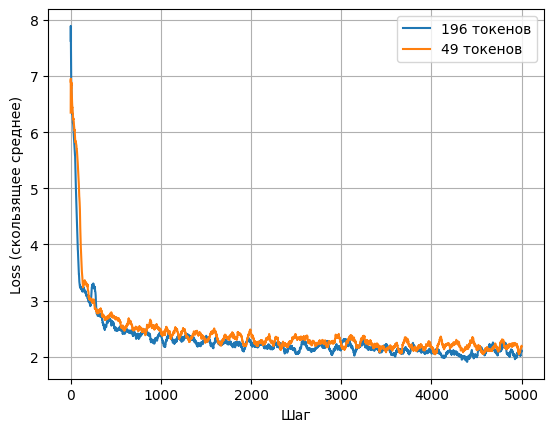

In [6]:
class Images(Dataset):
    def __len__(self): return len(train)
    def __getitem__(self,i):
        _,p,cs=train[i]
        with Image.open(p) as im: image=im.convert('RGB')
        return image,cs[0]
def collate(items): return [x[0] for x in items],[x[1] for x in items]
def step_loss(proj,images,captions,merge):
    with torch.no_grad(): v=encode_images(images)
    ids=tokenizer([x+tokenizer.eos_token for x in captions],padding=True,truncation=True,max_length=48,return_tensors='pt').to(device)
    vis=proj(v,merge).to(torch.float16); batch=len(images); plen=prompt_ids.shape[1]
    with torch.no_grad():
        prompt=llm.get_input_embeddings()(prompt_ids.expand(batch,-1)); txt=llm.get_input_embeddings()(ids.input_ids)
    embeds=torch.cat((vis,prompt,txt),dim=1)
    mask=torch.cat((torch.ones(batch,vis.shape[1]+plen,device=device,dtype=ids.attention_mask.dtype),ids.attention_mask),dim=1)
    labels=torch.cat((torch.full((batch,vis.shape[1]+plen),-100,device=device,dtype=torch.long),ids.input_ids.masked_fill(ids.attention_mask==0,-100)),dim=1)
    assert (labels[:,:vis.shape[1]+plen]==-100).all()
    return llm(inputs_embeds=embeds,attention_mask=mask,labels=labels,use_cache=False).loss
loader=DataLoader(Images(),batch_size=4,shuffle=True,generator=torch.Generator().manual_seed(SEED),collate_fn=collate,num_workers=2)
histories={}; elapsed={}; projs={}
for merge in [False,True]:
    torch.manual_seed(SEED); proj=Projector().to(device); opt=torch.optim.AdamW(proj.parameters(),lr=1e-3)
    sched=get_linear_schedule_with_warmup(opt,num_warmup_steps=max(1,int(.05*len(loader))),num_training_steps=len(loader))
    scaler=torch.amp.GradScaler('cuda'); losses=[]; start=time.perf_counter()
    for k,(images,captions) in enumerate(loader):
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda',dtype=torch.float16): loss=step_loss(proj,images,captions,merge)
        scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(proj.parameters(),1.0); scaler.step(opt); scaler.update(); sched.step()
        losses.append(float(loss.detach()))
        if (k+1)%100==0: print('merge',merge,'шаг',k+1,'/',len(loader),'loss',np.mean(losses[-100:]))
    elapsed[merge]=time.perf_counter()-start; histories[merge]=losses; projs[merge]=proj.eval()
    torch.save({'state':proj.state_dict(),'vision_revision':VR,'llm_revision':LR,'seed':SEED},f'projector_{49 if merge else 196}.pt')
for merge,losses in histories.items(): plt.plot(pd.Series(losses).rolling(50,min_periods=1).mean(),label=f'{49 if merge else 196} токенов')
plt.xlabel('Шаг'); plt.ylabel('Loss (скользящее среднее)'); plt.legend(); plt.grid(); plt.show()

## 4. Генерация и BLEU-4 на 500 изображениях

Для каждого изображения используются все доступные эталонные подписи COCO. Измеряется время обучения и длина визуального контекста.

In [7]:
from pycocoevalcap.bleu.bleu import Bleu
@torch.inference_mode()
def caption(proj,path,merge):
    with Image.open(path) as im: image=im.convert('RGB')
    vis=proj(encode_images([image]),merge).to(torch.float16)
    prompt=llm.get_input_embeddings()(prompt_ids)
    out=llm.generate(inputs_embeds=torch.cat((vis,prompt),dim=1),attention_mask=torch.ones(1,vis.shape[1]+prompt.shape[1],device=device,dtype=torch.long),max_new_tokens=48,do_sample=False,use_cache=True,pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0],skip_special_tokens=True).strip()
preds={}; rows=[]
for merge in [False,True]:
    results={}; refs={}
    for k,(iid,path,caps) in enumerate(val):
        results[iid]=[caption(projs[merge],path,merge)]; refs[iid]=caps
        if (k+1)%50==0: print('вариант',49 if merge else 196,'оценено',k+1)
    score,_=Bleu(4).compute_score(refs,results); preds[merge]=results
    rows.append({'Визуальные токены':49 if merge else 196,'BLEU-4':score[3],'Время обучения, с':elapsed[merge]})
display(pd.DataFrame(rows))
for iid,path,caps in val[:10]:
    print('ID',iid,'эталон:',caps[0], '\n196:',preds[False][iid][0], '\n49:',preds[True][iid][0], '\n')

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


вариант 196 оценено 50
вариант 196 оценено 100
вариант 196 оценено 150
вариант 196 оценено 200
вариант 196 оценено 250
вариант 196 оценено 300
вариант 196 оценено 350
вариант 196 оценено 400
вариант 196 оценено 450
вариант 196 оценено 500
{'testlen': 4825, 'reflen': 4807, 'guess': [4825, 4325, 3825, 3325], 'correct': [3411, 1559, 654, 279]}
ratio: 1.0037445392134379
вариант 49 оценено 50
вариант 49 оценено 100
вариант 49 оценено 150
вариант 49 оценено 200
вариант 49 оценено 250
вариант 49 оценено 300
вариант 49 оценено 350
вариант 49 оценено 400
вариант 49 оценено 450
вариант 49 оценено 500
{'testlen': 4863, 'reflen': 4842, 'guess': [4863, 4363, 3863, 3363], 'correct': [3350, 1472, 634, 284]}
ratio: 1.0043370508052447


,Визуальные токены,BLEU-4,"Время обучения, с"
0,196,0.245896,1148.341417
1,49,0.238235,728.550249


ID 337498 эталон: A large slice of pizza with cheese and marinara sauce on a plate.  
196: A plate of pizza topped with cheese and pepperoni. 
49: A pizza sitting on a plate with some sauce. 

ID 283070 эталон: some oranges that are sitting on some wood 
196: A wooden table with a glass of orange juice. 
49: A wooden table with a fruit knife and a glass of orange juice. 

ID 558558 эталон: A city traffic signal and street at night. 
196: A street with lots of traffic lights and cars. 
49: A street with traffic lights and cars. 

ID 294831 эталон: Two pieces of pizza are served on a plate. 
196: A person holding a piece of pizza on a plate. 
49: A pizza is sitting on a white plate. 

ID 279774 эталон: A baseball player is getting ready to hit a ball. 
196: A young boy is swinging a baseball bat. 
49: A young boy is swinging a baseball bat. 

ID 214539 эталон: A crowd is watching the two teams play soccer.  
196: A woman is playing soccer on a field. 
49: A woman is playing a game of soc

## 5. Анализ и контрольные вопросы

После выполнения классифицируйте ошибки на показанных примерах по изображению: выдуманный объект, неверный счёт, неверный атрибут. Категорию нельзя надёжно присвоить автоматически только по неполным подписям COCO.

LLM замораживают, чтобы проектор выучил отображение визуальных признаков в пространство уже обученной языковой модели при меньших затратах и без изменения её весов. После первого этапа ожидается базовое выравнивание изображения и текста; надёжное выполнение сложных инструкций и отсутствие галлюцинаций этот этап не гарантирует.